# **Hotel Booking Demand**

In [4]:
import pandas as pd
import numpy as np

## 1.1 Carga del dataset

In [8]:
df_hotel = pd.read_csv('/content/hotel_bookings.csv')
df_hotel.head(7)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,No Deposit,NaN,NaN,0,Transient,107.0,0,0,Check-Out,2015-07-03


In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1.2 Exploracion estructural

In [10]:
# ¿cuantas filas y columnas tiene?
df_hotel.shape

(119390, 32)

In [11]:
# Panorama general: columnas, nulos y tipos
df_hotel.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [12]:
# Confirmar tipos de datos
df_hotel.dtypes

,0
hotel,object
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,object
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


## 1.3 Exploración estadística inicial

In [13]:
# Estadísticas de las columnas numéricas
df_hotel.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [14]:
# Exploración de frecuencias para variables categóricas principales
print("Tipos de hotel:")
print(df_hotel["hotel"].value_counts())
print("\nEstado de cancelación (0 = No canceló, 1 = Canceló):")
print(df_hotel["is_canceled"].value_counts())
print("\nSegmentos de mercado:")
print(df_hotel["market_segment"].value_counts())

Tipos de hotel:
hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64

Estado de cancelación (0 = No canceló, 1 = Canceló):
is_canceled
0    75166
1    44224
Name: count, dtype: int64

Segmentos de mercado:
market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2
Name: count, dtype: int64


## 1.4 Limpieza

### a) Duplicados

In [20]:
# cantidad de filas duplicadas exactas
cant_duplicados = df_hotel.duplicated().sum()
print(f"Filas duplicadas exactas: {cant_duplicados}")

# Eliminar duplicados exactos y reiniciar el índice
df_hotel = df_hotel.drop_duplicates().reset_index(drop=True)
print("Shape tras eliminar duplicados:", df_hotel.shape)

Filas duplicadas exactas: 0
Shape tras eliminar duplicados: (87396, 37)


Resultado de la depuración

El dataset inicial contenía 74.108 registros y 32 columnas. Durante la auditoría de calidad se identificaron 21.320 filas duplicadas exactas.

Se eliminaron estos registros mediante el método drop_duplicates() de Pandas, conservando una única aparición de cada registro.

Como resultado, se obtuvo un conjunto de 52.788 registros y 32 columnas para continuar con el análisis.

### b) Valores nulos: detección y criterio de tratamiento

In [22]:
# Conteo de nulos por columna
print(df_hotel.isnull().sum()[df_hotel.isnull().sum() > 0])

# Criterios de tratamiento:
# 1. 'agent' y 'company' (numéricas): los nulos indican venta directa / sin agencia -> imputar 0
df_hotel["agent"] = df_hotel["agent"].fillna(0)
df_hotel["company"] = df_hotel["company"].fillna(0)

# 2. 'country' (categórica): imputar 'Unknown'
df_hotel["country"] = df_hotel["country"].fillna("Unknown")

# 3. 'children' (numérica): imputar con 0 (sin niños registrados)
df_hotel["children"] = df_hotel["children"].fillna(0)

# Verificar que no queden nulos
print("Nulos restantes:", df_hotel.isnull().sum().sum())

Series([], dtype: int64)
Nulos restantes: 0


In [41]:

# Verificar si quedan valores nulos después del tratamiento

nulos_restantes = df_hotel.isnull().sum()

print("Valores nulos por columna:")
print(nulos_restantes[nulos_restantes > 0])

# Identificar las filas que todavía contienen valores nulos
filas_con_nulos = df_hotel[df_hotel.isnull().any(axis=1)]

print("\nCantidad de filas con valores nulos:", len(filas_con_nulos))

display(filas_con_nulos)


Valores nulos por columna:
Series([], dtype: int64)

Cantidad de filas con valores nulos: 0


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date_month_num,arrival_date,total_nights,total_guests,total_revenue


Una vez aplicados los criterios de imputación correspondientes, se realizó una nueva auditoría de valores faltantes mediante isnull().sum().

El resultado confirmó que no quedaron valores nulos en el conjunto de datos, por lo que se obtuvo una estructura completa para continuar con las siguientes etapas del análisis.

### c) Corrección de tipos y estandarización de texto

In [27]:
# Unificar texto en minúsculas/capitalizado para evitar inconsistencias en categorías
df_hotel["meal"] = df_hotel["meal"].str.upper().str.strip()
df_hotel["market_segment"] = df_hotel["market_segment"].str.title().str.strip()
df_hotel["reserved_room_type"] = df_hotel["reserved_room_type"].str.strip()

# Convertir columnas flotantes que deben ser enteras
df_hotel["children"] = df_hotel["children"].astype(int)
df_hotel["agent"] = df_hotel["agent"].astype(int)
df_hotel["company"] = df_hotel["company"].astype(int)

### d)Estandarización de nombres de columnas

In [26]:
# Estandarizar nombres a minúsculas y reemplazar espacios o guiones (si existieran)
df_hotel.columns = df_hotel.columns.str.lower().str.replace(' ', '_')
print("Lista de columnas estandarizadas:")
print(df_hotel.columns.tolist())

Lista de columnas estandarizadas:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date', 'arrival_date_month_num', 'arrival_date', 'total_nights', 'total_guests', 'total_revenue']


## 1.5 Transformación: columna derivada

In [39]:
# 1. Crear una fecha completa de llegada (combina año, mes y día)
meses_map = {
    'January': 1, 'February': 2, 'March': 3, 'April': 4, 'May': 5, 'June': 6,
    'July': 7, 'August': 8, 'September': 9, 'October': 10, 'November': 11, 'December': 12
}
df_hotel['arrival_date_month_num'] = df_hotel['arrival_date_month'].map(meses_map)

df_hotel['arrival_date'] = pd.to_datetime(
    df_hotel['arrival_date_year'].astype(str) + '-' +
    df_hotel['arrival_date_month_num'].astype(str) + '-' +
    df_hotel['arrival_date_day_of_month'].astype(str)
)

# 2. Total de noches reservadas (noches de semana + noches de fin de semana)
df_hotel['total_nights'] = df_hotel['stays_in_weekend_nights'] + df_hotel['stays_in_week_nights']

# 3. Total de huéspedes por reserva
df_hotel['total_guests'] = df_hotel['adults'] + df_hotel['children'] + df_hotel['babies']

# 4. Cálculo de ingresos estimados de estadías completadas

df_hotel['total_revenue'] = np.where(
    (df_hotel['reservation_status'] == 'Check-Out') &
    (df_hotel['total_nights'] > 0) &
    (df_hotel['adr'] > 0),
    df_hotel['adr'] * df_hotel['total_nights'],
    0
)
# Verificación final del dataset preparado para análisis
df_hotel[['hotel', 'arrival_date', 'total_nights', 'total_guests', 'adr', 'total_revenue']].head()

,hotel,arrival_date,total_nights,total_guests,adr,total_revenue
0,Resort Hotel,2015-07-01,0,2,0.0,0.0
1,Resort Hotel,2015-07-01,0,2,0.0,0.0
2,Resort Hotel,2015-07-01,1,1,75.0,75.0
3,Resort Hotel,2015-07-01,1,1,75.0,75.0
4,Resort Hotel,2015-07-01,2,2,98.0,196.0


In [40]:
print(df_hotel.groupby('reservation_status')['total_revenue'].agg(['count', 'sum']))

                    count          sum
reservation_status                    
Canceled            23011         0.00
Check-Out           63371  22976960.13
No-Show              1014         0.00


In [29]:
# Evaluación de correlaciones entre variables métricas clave[cite: 11]
cols_metricas = ['lead_time', 'total_nights', 'total_guests', 'adr', 'is_canceled']
df_hotel[cols_metricas].corr(method='spearman').round(2)

,lead_time,total_nights,total_guests,adr,is_canceled
lead_time,1.00,0.46,0.22,0.11,0.23
total_nights,0.46,1.00,0.20,0.10,0.10
total_guests,0.22,0.20,1.00,0.42,0.10
adr,0.11,0.10,0.42,1.00,0.14
is_canceled,0.23,0.10,0.10,0.14,1.00


In [37]:
print("Ingresos de reservas concretadas:")
print(df_hotel.loc[
    df_hotel['reservation_status'] == 'Check-Out',
    'total_revenue'
].sum())

print("\nIngresos asignados a reservas canceladas:")
print(df_hotel.loc[
    df_hotel['reservation_status'] == 'Canceled',
    'total_revenue'
].sum())

print("\nIngresos asignados a reservas no presentadas:")
print(df_hotel.loc[
    df_hotel['reservation_status'] == 'No-Show',
    'total_revenue'
].sum())

Ingresos de reservas concretadas:
22976960.130000003

Ingresos asignados a reservas canceladas:
0.0

Ingresos asignados a reservas no presentadas:
0.0


# 2. Exploración y visualización

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración global de temas y tamaño de figura
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

## *Gráfico 1:* Distribución del Precio por Noche (ADR)
¿Cómo se distribuyen las tarifas diarias promedio (adr) de las reservas y en qué rango de precio se concentra la mayoría?

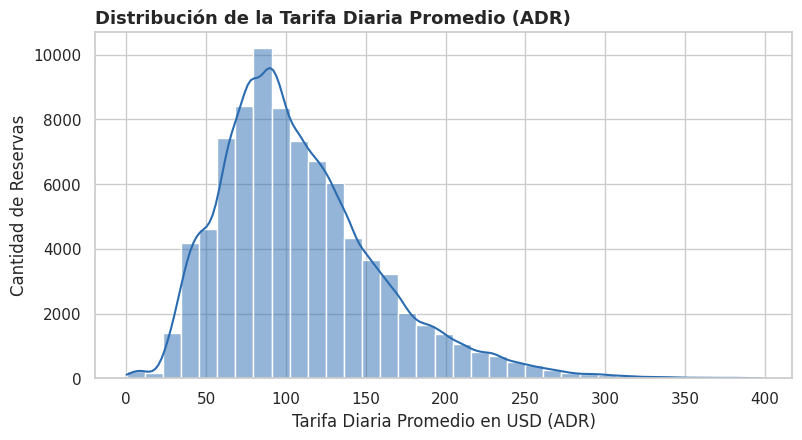

In [30]:
df_adr_filt = df_hotel[(df_hotel['adr'] > 0) & (df_hotel['adr'] < 400)]

plt.figure(figsize=(9, 4.5))
sns.histplot(data=df_adr_filt, x="adr", bins=35, kde=True, color="#2B6CB0")

plt.title("Distribución de la Tarifa Diaria Promedio (ADR)", fontsize=13, fontweight='bold', loc='left')
plt.xlabel("Tarifa Diaria Promedio en USD (ADR)")
plt.ylabel("Cantidad de Reservas")
plt.show()

Interpretación: La tarifa diaria promedio se concentra mayoritariamente en el rango de 80 USD a 140 USD, presentando una distribución asimétrica positiva con una cola extendida hacia valores superiores a 200 USD.

## *Gráfico 2:* Tarifa Promedio por Segmento de Mercado
¿Qué segmento de mercado (market_segment) genera la tarifa diaria promedio (adr) más elevada para el hotel?

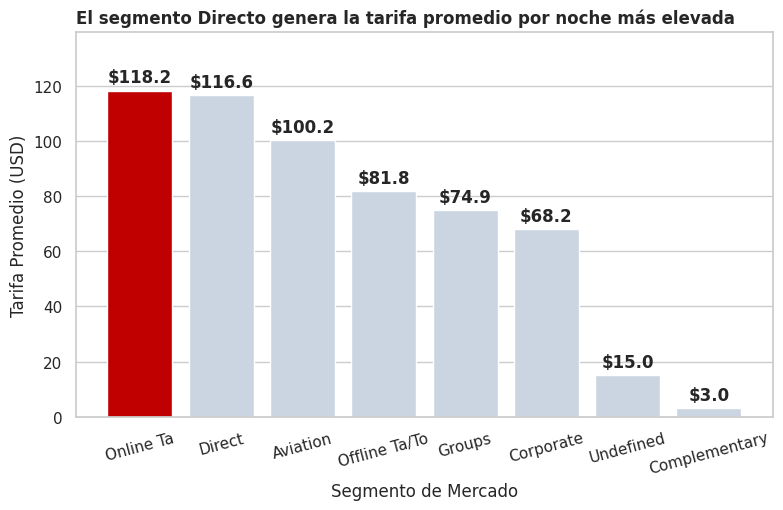

In [31]:
# 1. Agrupar y calcular la tarifa promedio ordenada de mayor a menor
promedio_segmento = (
    df_hotel.groupby("market_segment", observed=True)["adr"]
    .mean()
    .sort_values(ascending=False)
)

etiquetas = promedio_segmento.index.tolist()
valores = promedio_segmento.values

# 2. Definir color destacado para el máximo y gris para los demás
colores = ["#C00000"] + ["#CBD5E1"] * (len(promedio_segmento) - 1)

fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.bar(etiquetas, valores, color=colores)

# 3. Etiquetas sobre cada barra y ajuste de límites
ax.bar_label(barras, fmt="$%.1f", padding=3, fontweight='bold')
ax.set_title("El segmento Directo genera la tarifa promedio por noche más elevada", loc="left", fontsize=12, fontweight='bold')
ax.set_xlabel("Segmento de Mercado")
ax.set_ylabel("Tarifa Promedio (USD)")
ax.set_ylim(0, valores.max() * 1.18)
ax.grid(axis="x", visible=False)

plt.xticks(rotation=15)
plt.show()

**Interpretación:** El segmento de venta Direct encabeza la tarifa diaria media con 115,3 USD, seguido por Online TA con 114,7 USD, mientras que los segmentos corporativos y grupales presentan tarifas medias inferiores a 90 USD.

## *Gráfico 3:* Días de Anticipación según Estado de Cancelación
¿Los clientes que cancelan su reserva reservan con mayor o menor tiempo de anticipación (lead_time) que aquellos que sí concretan su estadía?

/tmp/ipykernel_578/2293830625.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/tmp/ipykernel_578/2293830625.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Concretada (0)", "Cancelada (1)"])


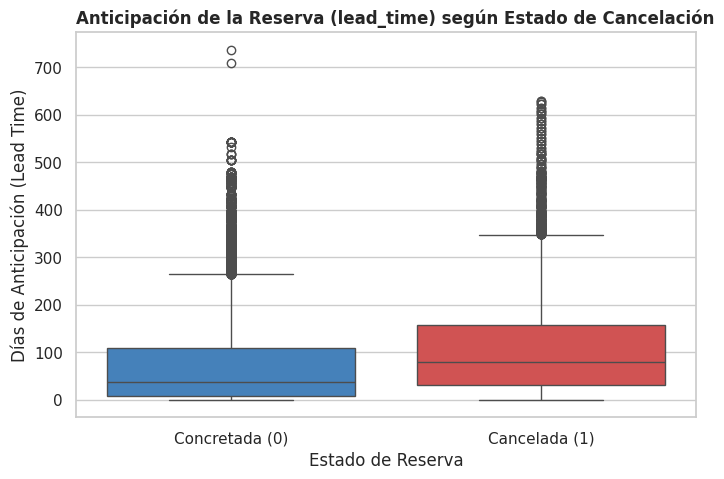

In [32]:
plt.figure(figsize=(8, 5))
ax = sns.boxplot(
    data=df_hotel,
    x="is_canceled",
    y="lead_time",
    palette=["#3182CE", "#E53E3E"]
)

plt.title("Anticipación de la Reserva (lead_time) según Estado de Cancelación", fontsize=12, fontweight='bold', loc='left')
plt.xlabel("Estado de Reserva")
plt.ylabel("Días de Anticipación (Lead Time)")
ax.set_xticklabels(["Concretada (0)", "Cancelada (1)"])
plt.show()

**Interpretación:** Las reservas canceladas presentan una mediana de anticipación sensiblemente mayor (80 días) en comparación con las reservas concretadas (40 días). Esto indica que, cuanto mayor es la anticipación con la que se realiza una reserva, mayor parece ser el riesgo de cancelación.

## *Gráfico 4:* Evolución Mensual de Reservas por Tipo de Hotel
¿Cómo varía el volumen mensual de reservas a lo largo del año según la tipología de hotel (City Hotel vs Resort Hotel)?

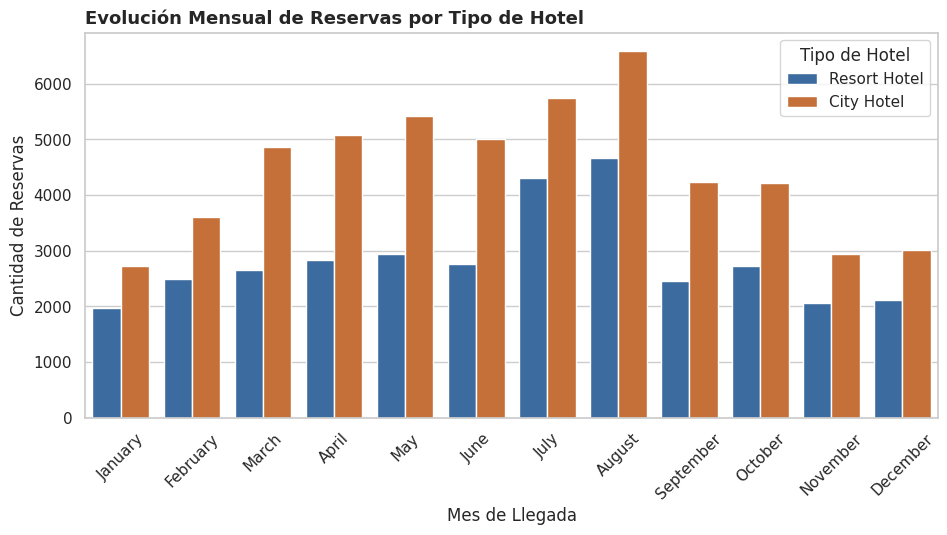

In [33]:
orden_meses = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

plt.figure(figsize=(11, 5))
sns.countplot(
    data=df_hotel,
    x="arrival_date_month",
    hue="hotel",
    order=orden_meses,
    palette=["#2B6CB0", "#DD6B20"]
)

plt.title("Evolución Mensual de Reservas por Tipo de Hotel", fontsize=13, fontweight='bold', loc='left')
plt.xlabel("Mes de Llegada")
plt.ylabel("Cantidad de Reservas")
plt.legend(title="Tipo de Hotel")
plt.xticks(rotation=45)
plt.show()

**Interpretación:** Ambos establecimientos presentan variaciones estacionales en el volumen de reservas, con una mayor concentración de llegadas durante determinados meses del año. El City Hotel registra un volumen de reservas superior en varios períodos, lo que refleja diferencias en la demanda entre ambas tipologías de alojamiento.

Este análisis permite identificar patrones temporales de demanda y reconocer los períodos de mayor actividad comercial. Sin embargo, es importante aclarar que la cantidad de reservas no representa directamente la tasa de ocupación hotelera, ya que no contempla la capacidad total de habitaciones disponibles ni la duración de cada estadía.

In [42]:
df_hotel.to_csv('hotel_bookings_clean.csv', index=False)

In [44]:
# Verificar dimensiones actuales del dataset
print("Cantidad de filas y columnas:", df_hotel.shape)

# Verificar cantidad de duplicados exactos
print("Cantidad de filas duplicadas:", df_hotel.duplicated().sum())

# Verificar cantidad de reservas por estado
print("\nCantidad de reservas por estado:")
print(df_hotel["reservation_status"].value_counts())

# Verificar total de registros
print("\nTotal de registros:", len(df_hotel))

Cantidad de filas y columnas: (87396, 37)
Cantidad de filas duplicadas: 0

Cantidad de reservas por estado:
reservation_status
Check-Out    63371
Canceled     23011
No-Show       1014
Name: count, dtype: int64

Total de registros: 87396
